# Lista 05 — Apriori no Titanic

Execute as células na ordem, com `titanic completo.csv` na mesma pasta. Resultados em `resultados/` e gráficos em `figuras/`.


In [1]:
# Instale somente se necessário no ambiente do notebook:
# %pip install pandas apyori==1.1.2 matplotlib

## 1. Bibliotecas e dados


In [2]:
from pathlib import Path
from itertools import combinations
import json
import math
import hashlib

import pandas as pd
from apyori import apriori

PASTA = Path.cwd()
if not (PASTA / "titanic completo.csv").exists():
    PASTA = Path.cwd() / "Lists" / "List05"
SAIDA = PASTA / "resultados"
SAIDA.mkdir(exist_ok=True)
ARQUIVO = PASTA / "titanic completo.csv"
base = pd.read_csv(ARQUIVO)
n = len(base)
assert n == 1309 and set(base.survived.unique()) == {0, 1}
print(f"Base: {n} passageiros e {base.shape[1]} atributos.")
print(base.isna().sum().to_string())


Base: 1309 passageiros e 14 atributos.
pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564


## 2. Tratamento dos dados

Preenchemos idade e tarifa pela mediana e embarque pela moda, sem usar sobrevivência. Idade, tarifa e tamanho da família são agrupados em faixas.


In [3]:
dados = base.copy()
medianas_idade = dados.groupby(["pclass", "sex"])["age"].median()
dados["age"] = dados["age"].fillna(
    dados.groupby(["pclass", "sex"])["age"].transform("median")
).fillna(dados["age"].median())
dados["fare"] = dados["fare"].fillna(
    dados.groupby("pclass")["fare"].transform("median")
).fillna(dados["fare"].median())

dados["embarked"] = dados["embarked"].fillna(dados["embarked"].mode().iloc[0])

categorias = pd.DataFrame(index=dados.index)
categorias["Classe"] = dados["pclass"].map({1: "1", 2: "2", 3: "3"})
categorias["Sexo"] = dados["sex"].map({"female": "Feminino", "male": "Masculino"})
categorias["Idade"] = pd.cut(
    dados["age"], [0, 18, 23, 41, float("inf")], right=False,
    labels=["0-17", "18-22", "23-40", "41+"]
).astype(str)
categorias["Tarifa"] = pd.cut(
    dados["fare"], [0, 10, 30, 100, float("inf")], right=False,
    labels=["0-<10", "10-<30", "30-<100", "100+"]
).astype(str)
categorias["Familia"] = pd.cut(
    dados["sibsp"] + dados["parch"] + 1,
    [1, 2, 5, float("inf")], right=False, labels=["1", "2-4", "5+"]
).astype(str)
categorias["Embarque"] = dados["embarked"]
categorias["Sobreviveu"] = dados["survived"].map({0: "Nao", 1: "Sim"})
assert not categorias.isna().any().any()
assert not categorias.isin(["nan"]).any().any()
categorias.to_csv(SAIDA / "base_categorica.csv", index=False)
distribuicoes = pd.concat([
    categorias[c].value_counts().rename_axis("valor").reset_index(name="n").assign(atributo=c)
    for c in categorias
], ignore_index=True)[["atributo", "valor", "n"]]
distribuicoes["percentual"] = distribuicoes["n"] / n * 100
distribuicoes.to_csv(SAIDA / "distribuicoes.csv", index=False)
print("Medianas para idade:\n", medianas_idade.to_string())
print("Distribuições finais:\n", distribuicoes.to_string(index=False))


Medianas para idade:
 pclass  sex   
1       female    36.0
        male      42.0
2       female    28.0
        male      29.5
3       female    22.0
        male      25.0
Distribuições finais:
   atributo     valor   n  percentual
    Classe         3 709   54.163484
    Classe         1 323   24.675325
    Classe         2 277   21.161192
      Sexo Masculino 843   64.400306
      Sexo  Feminino 466   35.599694
     Idade     23-40 659   50.343774
     Idade       41+ 252   19.251337
     Idade     18-22 244   18.640183
     Idade      0-17 154   11.764706
    Tarifa     0-<10 492   37.585943
    Tarifa    10-<30 467   35.676089
    Tarifa   30-<100 266   20.320856
    Tarifa      100+  84    6.417112
   Familia         1 790   60.351413
   Familia       2-4 437   33.384263
   Familia        5+  82    6.264324
  Embarque         S 916   69.977082
  Embarque         C 270   20.626432
  Embarque         Q 123    9.396486
Sobreviveu       Nao 809   61.802903
Sobreviveu       Sim 500 

## 3. Transações

Cada passageiro reúne características e seus complementos (`NAO`). Ausência de uma característica não significa dado faltante.


In [4]:
presenca = pd.get_dummies(categorias, prefix_sep="=", dtype=bool)
preditores = [c for c in presenca if not c.startswith("Sobreviveu=")]
ausencia = (~presenca[preditores]).rename(columns=lambda c: "NAO " + c)
binaria = pd.concat([presenca, ausencia], axis=1)
transacoes = [list(binaria.columns[linha]) for linha in binaria.to_numpy()]
assert len(binaria.columns) == 40
assert all(len(t) == 20 for t in transacoes)
for item in preditores:
    assert (binaria[item] ^ binaria["NAO " + item]).all()
binaria.astype(int).to_csv(SAIDA / "base_binaria.csv", index=False)
print(f"Matriz binária: {binaria.shape}; 20 itens ativos por passageiro.")
print("Exemplo de transação:", transacoes[0])


Matriz binária: (1309, 40); 20 itens ativos por passageiro.
Exemplo de transação: ['Classe=1', 'Sexo=Feminino', 'Idade=23-40', 'Tarifa=100+', 'Familia=1', 'Embarque=S', 'Sobreviveu=Sim', 'NAO Classe=2', 'NAO Classe=3', 'NAO Sexo=Masculino', 'NAO Idade=0-17', 'NAO Idade=18-22', 'NAO Idade=41+', 'NAO Tarifa=0-<10', 'NAO Tarifa=10-<30', 'NAO Tarifa=30-<100', 'NAO Familia=2-4', 'NAO Familia=5+', 'NAO Embarque=C', 'NAO Embarque=Q']


## 4. Apriori

Comparamos seis combinações de suporte e confiança, com até três itens por regra. Mantemos consequente único, lift ≥ 1,10 e ganho de confiança ≥ 2 pontos percentuais para antecedentes compostos. Sobrevivência aparece apenas no consequente.


In [5]:
CONFIGURACOES = [(0.05, 0.60), (0.05, 0.70), (0.10, 0.60),
                 (0.10, 0.70), (0.15, 0.70), (0.10, 0.80)]
SUPORTE_ESCOLHIDO, CONFIANCA_ESCOLHIDA = 0.05, 0.70


def atributo(item):
    return item.removeprefix("NAO ").split("=", 1)[0]


def extrair_regra(a, b, suporte, confianca, lift):
    return {"antecedente": tuple(sorted(a)), "consequente": tuple(sorted(b)),
            "suporte": suporte, "confianca": confianca, "lift": lift,
            "n_conjunto": round(suporte * n),
            "n_antecedente": round(suporte / confianca * n)}


def admissivel(r):
    itens = r["antecedente"] + r["consequente"]
    if len({atributo(x) for x in itens}) != len(itens):
        return False
    if any(x.startswith("NAO Sexo=") for x in itens):
        return False
    if any(atributo(x) == "Sobreviveu" for x in r["antecedente"]):
        return False
    return len(r["consequente"]) == 1 and r["lift"] >= 1.10 - 1e-12


def sem_redundancia(r):
    a, b = r["antecedente"], r["consequente"]
    for k in range(1, len(a)):
        for sub in combinations(a, k):
            mascara = binaria[list(sub)].all(axis=1)
            conf_sub = binaria.loc[mascara, list(b)].all(axis=1).mean()
            if r["confianca"] - conf_sub < 0.02 - 1e-12:
                return False
    return True


def salvar_regras(regras, nome):
    tabela = pd.DataFrame(regras)
    if len(tabela):
        tabela = tabela.sort_values(["lift", "confianca", "suporte"], ascending=False)
        for coluna in ["antecedente", "consequente"]:
            tabela[coluna] = tabela[coluna].map(lambda xs: " & ".join(xs))
    tabela.to_csv(SAIDA / nome, index=False)
    return tabela


comparacoes = []
for suporte_min, confianca_min in CONFIGURACOES:
    saida = list(apriori(transacoes, min_support=suporte_min,
                        min_confidence=confianca_min, max_length=3))
    brutas = [extrair_regra(s.items_base, s.items_add, r.support, s.confidence, s.lift)
              for r in saida for s in r.ordered_statistics
              if s.items_base and s.items_add]
    filtradas = [r for r in brutas if admissivel(r)]
    finais = [r for r in filtradas if sem_redundancia(r)]
    alvo = [r for r in finais if atributo(r["consequente"][0]) == "Sobreviveu"]
    frequentes = list(apriori(transacoes, min_support=suporte_min,
                             min_confidence=0, max_length=3))
    comparacoes.append({"suporte_min": suporte_min, "confianca_min": confianca_min,
                        "itemsets_frequentes": len(frequentes), "regras_brutas": len(brutas),
                        "apos_filtros": len(filtradas), "nao_redundantes": len(finais),
                        "sobreviveu_sim": sum(r["consequente"] == ("Sobreviveu=Sim",) for r in alvo),
                        "sobreviveu_nao": sum(r["consequente"] == ("Sobreviveu=Nao",) for r in alvo)})
    tag = f"s{round(suporte_min*100):02d}_c{round(confianca_min*100):02d}"
    salvar_regras(brutas, f"regras_brutas_{tag}.csv")
    salvar_regras(finais, f"regras_filtradas_{tag}.csv")
    if (suporte_min, confianca_min) == (SUPORTE_ESCOLHIDO, CONFIANCA_ESCOLHIDA):
        escolhidas, alvo_escolhido = finais, alvo

comparacao = pd.DataFrame(comparacoes)
comparacao.to_csv(SAIDA / "comparacao_configuracoes.csv", index=False)
regras_finais = salvar_regras(escolhidas, "regras_finais.csv")
regras_alvo = salvar_regras(alvo_escolhido, "regras_sobrevivencia.csv")
print(comparacao.to_string(index=False))
print("Regras finais sobre sobrevivência:\n", regras_alvo.to_string(index=False))


 suporte_min  confianca_min  itemsets_frequentes  regras_brutas  apos_filtros  nao_redundantes  sobreviveu_sim  sobreviveu_nao
        0.05            0.6                 6234          12464          1573              778              41              56
        0.05            0.7                 6234           9186          1255              578              17              44
        0.10            0.6                 4453          10378          1128              542              20              49
        0.10            0.7                 4453           7519           895              397               9              38
        0.15            0.7                 3156           6300           688              304               5              37
        0.10            0.8                 4453           4939           559              225               4              17
Regras finais sobre sobrevivência:
                         antecedente    consequente  suporte  confianca     

## 5. Verificação das métricas


In [6]:
assert "survived" in base.columns and "survived" in dados.columns
assert (binaria["Sobreviveu=Sim"].astype(int) == base["survived"]).all()
assert {"Embarque=C", "Embarque=Q", "Embarque=S"}.issubset(binaria.columns)
for r in escolhidas:
    assert all(atributo(x) != "Sobreviveu" for x in r["antecedente"])
    a = binaria[list(r["antecedente"])].all(axis=1)
    b = binaria[list(r["consequente"])].all(axis=1)
    s, c, l = (a & b).mean(), b[a].mean(), b[a].mean() / b.mean()
    assert math.isclose(r["suporte"], s, abs_tol=1e-12)
    assert math.isclose(r["confianca"], c, abs_tol=1e-12)
    assert math.isclose(r["lift"], l, abs_tol=1e-12)

resumo = {"n": n, "sobreviventes": int(base.survived.sum()),
          "nao_sobreviventes": int((base.survived == 0).sum()),
          "ausentes": {c: int(v) for c, v in base.isna().sum().items()},
          "idade_mediana_por_grupo": {f"{c}/{s}": float(v) for (c, s), v in medianas_idade.items()},
          "csv_sha256": hashlib.sha256(ARQUIVO.read_bytes()).hexdigest(),
          "configuracao": {"suporte": SUPORTE_ESCOLHIDO, "confianca": CONFIANCA_ESCOLHIDA,
                           "max_length": 3, "lift_min": 1.10, "ganho_min": 0.02},
          "regras_sobrevivencia": alvo_escolhido}
(SAIDA / "resumo.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Verificação concluída: métricas de {len(escolhidas)} regras conferidas diretamente.")


Verificação concluída: métricas de 578 regras conferidas diretamente.


## 6. Gráficos


In [7]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Markdown

FIGURAS = PASTA / "figuras"
FIGURAS.mkdir(exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#26364a",
    "text.color": "#26364a", "xtick.color": "#465569", "ytick.color": "#465569",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "pdf.fonttype": 42,
})
AZUL, VERDE, CORAL = "#355C86", "#167D8D", "#C76751"

def salvar_figura(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURAS / f"{nome}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Versões:", pd.__version__, matplotlib.__version__)


Versões: 2.2.3 3.11.2


### Sobrevivência por perfil

`n` indica o tamanho do grupo; o tracejado mostra a taxa global.


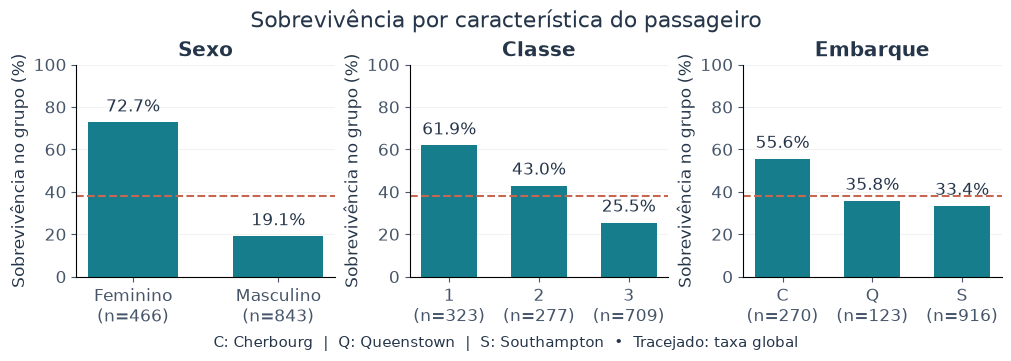

In [8]:
perfil = categorias.copy()
perfil["sobreviveu_num"] = base["survived"]
resumos_perfil = []
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
for ax, atributo_plot, ordem in zip(axes, ["Sexo", "Classe", "Embarque"],
                                   [["Feminino", "Masculino"], ["1", "2", "3"], ["C", "Q", "S"]]):
    tab = perfil.groupby(atributo_plot)["sobreviveu_num"].agg(["mean", "count", "sum"]).reindex(ordem)
    resumos_perfil.append(tab.reset_index().rename(columns={atributo_plot:"categoria"}).assign(atributo=atributo_plot))
    labels = [f"{v}\n(n={int(tab.loc[v, 'count'])})" for v in ordem]
    barras = ax.bar(labels, tab["mean"]*100, color=VERDE, width=.62)
    ax.bar_label(barras, labels=[f"{x*100:.1f}%" for x in tab["mean"]], padding=5)
    ax.axhline(base.survived.mean()*100, color=CORAL, ls="--", lw=1.5)
    ax.set_ylim(0, 100)
    ax.set_title(atributo_plot)
    ax.set_ylabel("Sobrevivência no grupo (%)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.16)
fig.suptitle("Sobrevivência por característica do passageiro", fontsize=16)
fig.supxlabel("C: Cherbourg  |  Q: Queenstown  |  S: Southampton  •  Tracejado: taxa global", fontsize=11)
pd.concat(resumos_perfil, ignore_index=True).to_csv(SAIDA / "taxas_por_perfil.csv", index=False)
salvar_figura(fig, "01_sobrevivencia_por_perfil")


### Classe e porto de embarque


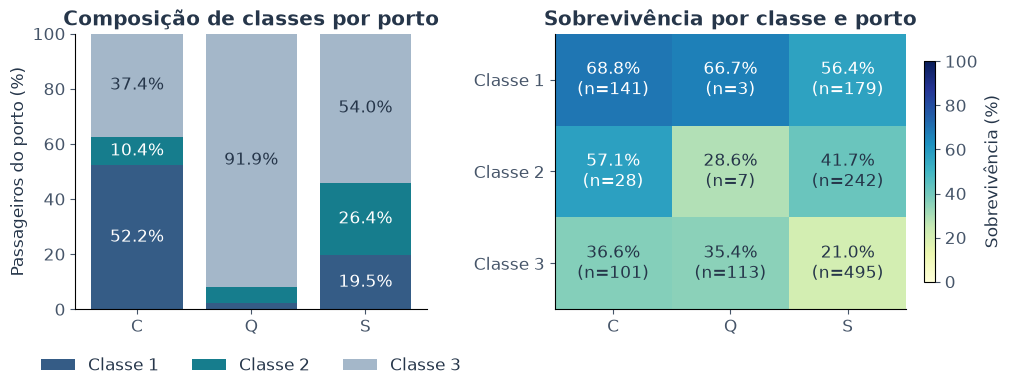

                     mean  count  sum
Classe Embarque                      
1      C         0.687943    141   97
       Q         0.666667      3    2
       S         0.564246    179  101
2      C         0.571429     28   16
       Q         0.285714      7    2
       S         0.417355    242  101
3      C         0.366337    101   37
       Q         0.353982    113   40
       S         0.210101    495  104


In [9]:
contagens = pd.crosstab(categorias["Embarque"], categorias["Classe"]).reindex(index=["C","Q","S"], columns=["1","2","3"])
composicao = contagens.div(contagens.sum(axis=1), axis=0)*100
estratos = perfil.groupby(["Classe", "Embarque"])["sobreviveu_num"].agg(["mean", "count", "sum"])
estratos.to_csv(SAIDA / "sobrevivencia_classe_embarque.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
base_barra = np.zeros(3)
for classe, cor in zip(["1", "2", "3"], [AZUL, VERDE, "#A4B7C9"]):
    valores = composicao[classe].to_numpy()
    axes[0].bar(composicao.index, valores, bottom=base_barra, color=cor, label=f"Classe {classe}")
    for i, valor in enumerate(valores):
        if valor >= 7:
            axes[0].text(i, base_barra[i]+valor/2, f"{valor:.1f}%", ha="center", va="center", color="white" if classe != "3" else "#26364a")
    base_barra += valores
axes[0].set_title("Composição de classes por porto")
axes[0].set_ylabel("Passageiros do porto (%)")
axes[0].set_ylim(0,100)
axes[0].legend(loc="upper center", bbox_to_anchor=(.5,-.12), ncol=3, frameon=False)
matriz = estratos["mean"].unstack("Embarque").reindex(index=["1","2","3"], columns=["C","Q","S"])*100
im = axes[1].imshow(matriz, cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
axes[1].set_xticks(range(3), ["C", "Q", "S"])
axes[1].set_yticks(range(3), ["Classe 1", "Classe 2", "Classe 3"])
axes[1].set_title("Sobrevivência por classe e porto")
for i, classe in enumerate(["1","2","3"]):
    for j, porto in enumerate(["C","Q","S"]):
        linha = estratos.loc[(classe, porto)]
        axes[1].text(j, i, f"{linha['mean']*100:.1f}%\n(n={int(linha['count'])})", ha="center", va="center", color="white" if linha['mean']>.55 else "#26364a")
fig.colorbar(im, ax=axes[1], label="Sobrevivência (%)", shrink=.8)
salvar_figura(fig, "02_embarque_e_classe")
print(estratos.to_string())


### Regras por configuração


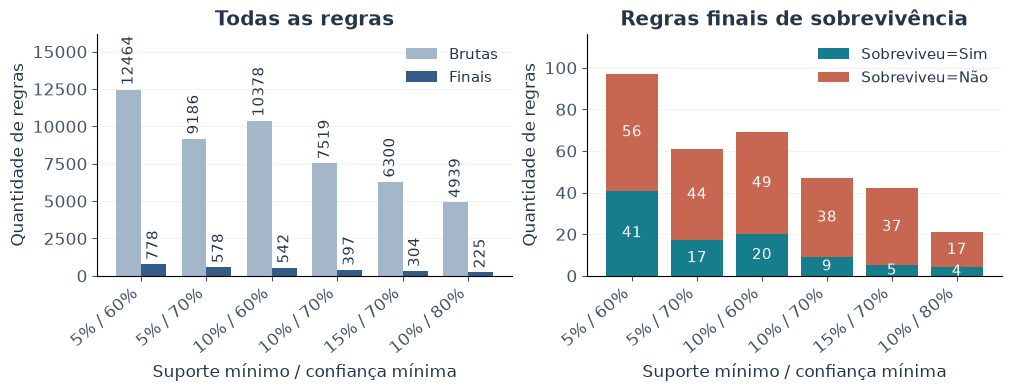

In [10]:
rotulos = [f"{s:.0%} / {c:.0%}" for s, c in zip(comparacao.suporte_min, comparacao.confianca_min)]
x = np.arange(len(rotulos))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for deslocamento, coluna, cor, legenda in [(-.19,"regras_brutas","#A4B7C9","Brutas"),(.19,"nao_redundantes",AZUL,"Finais")]:
    barras = axes[0].bar(x+deslocamento, comparacao[coluna], .38, color=cor, label=legenda)
    axes[0].bar_label(barras, padding=3, fontsize=11, rotation=90)
axes[0].set_ylim(0, comparacao.regras_brutas.max()*1.3)
axes[0].set_title("Todas as regras")
axes[0].set_ylabel("Quantidade de regras")
b1=axes[1].bar(x, comparacao.sobreviveu_sim, color=VERDE, label="Sobreviveu=Sim")
b2=axes[1].bar(x, comparacao.sobreviveu_nao, bottom=comparacao.sobreviveu_sim, color=CORAL, label="Sobreviveu=Não")
axes[1].bar_label(b1, label_type="center", color="white", fontsize=11)
axes[1].bar_label(b2, label_type="center", color="white", fontsize=11)
axes[1].set_title("Regras finais de sobrevivência")
axes[1].set_ylim(0, (comparacao.sobreviveu_sim+comparacao.sobreviveu_nao).max()*1.2)
axes[1].set_ylabel("Quantidade de regras")
for ax in axes:
    ax.set_xticks(x, rotulos, rotation=40, ha="right")
    ax.set_xlabel("Suporte mínimo / confiança mínima")
    ax.legend(loc="upper right", frameon=False, fontsize=11)
    ax.set_axisbelow(True); ax.grid(axis="y", alpha=.15)
salvar_figura(fig, "03_comparacao_configuracoes")


### Cinco regras com maior lift por desfecho


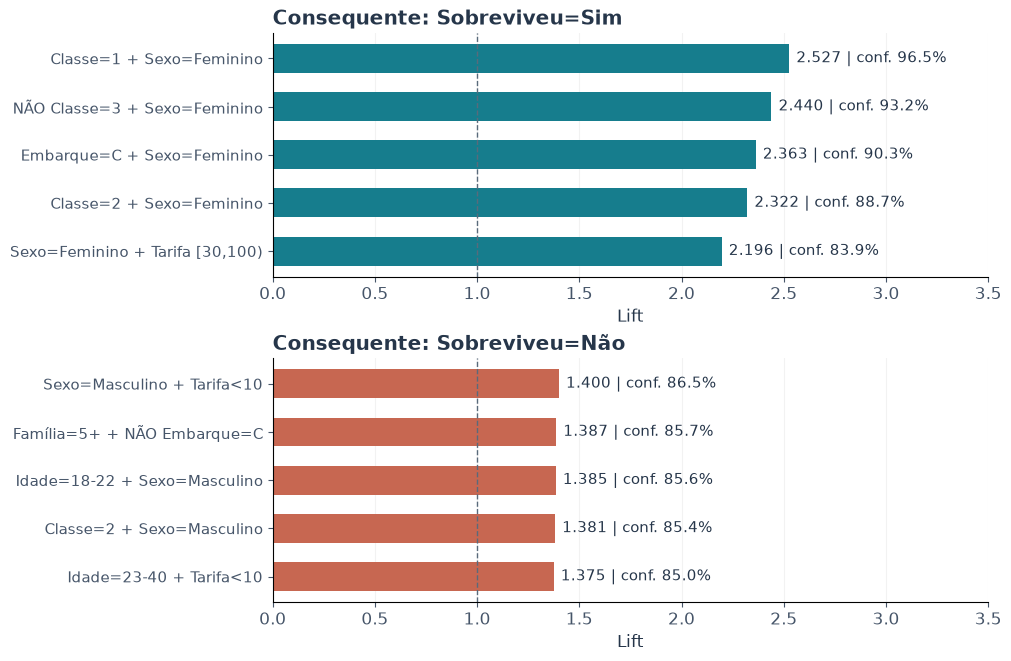

In [11]:
def rotulo_regra(s):
    return (s.replace("NAO ", "NÃO ").replace("Familia", "Família")
             .replace(" & ", " + ").replace("Tarifa=0-<10", "Tarifa<10")
             .replace("Tarifa=30-<100", "Tarifa [30,100)"))

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), layout="constrained")
for ax, destino, cor in zip(axes, ["Sim", "Nao"], [VERDE, CORAL]):
    top = regras_alvo[regras_alvo.consequente == f"Sobreviveu={destino}"].head(5)
    ys = np.arange(len(top))
    ax.barh(ys, top.lift, color=cor, height=.6)
    ax.set_yticks(ys, [rotulo_regra(x) for x in top.antecedente], fontsize=11)
    ax.invert_yaxis()
    for y, (_, r) in zip(ys, top.iterrows()):
        ax.text(r.lift+.035, y, f"{r.lift:.3f} | conf. {r.confianca:.1%}", va="center", fontsize=11)
    ax.axvline(1, ls="--", color="#596A7B", lw=1)
    ax.set_xlim(0, 3.5)
    ax.set_xlabel("Lift")
    ax.set_title(f"Consequente: Sobreviveu={'Não' if destino == 'Nao' else 'Sim'}", loc="left")
    ax.set_axisbelow(True); ax.grid(axis="x", alpha=.16)
salvar_figura(fig, "04_regras_maior_lift")


## 7. Interpretação das regras


In [12]:
selecoes = [
    ("Classe=1 & Sexo=Feminino", "Sim", "A sobrevivência das mulheres da primeira classe é muito superior à taxa global."),
    ("NAO Classe=3 & Sexo=Feminino", "Sim", "A ausência da terceira classe reúne mulheres das classes 1 e 2 em um perfil mais abrangente."),
    ("Classe=2 & Sexo=Feminino", "Sim", "O suporte de 5% preserva este grupo, que não atingiria suporte de 10%."),
    ("Sexo=Masculino & Tarifa=0-<10", "Nao", "Homens com tarifa baixa apresentam maior frequência de não sobrevivência; a tarifa não é uma causa demonstrada."),
    ("NAO Classe=1 & Sexo=Masculino", "Nao", "A negação resume homens das classes 2 e 3."),
    ("NAO Classe=1 & NAO Familia=2-4", "Nao", "Dois itens de ausência: classes 2 ou 3 e passageiros sozinhos ou em famílias de pelo menos cinco integrantes."),
    ("NAO Idade=18-22 & Sexo=Feminino", "Sim", "O complemento reúne três faixas etárias, cuja análise depende da imputação."),
    ("Familia=5+", "Nao", "Famílias maiores formam um grupo pequeno, preservado pelo suporte mínimo escolhido."),
]
for i, (a, b, comentario) in enumerate(selecoes,1):
    r = regras_alvo[(regras_alvo.antecedente==a)&(regras_alvo.consequente==f"Sobreviveu={b}")].iloc[0]
    display(Markdown(f"**{i}. {rotulo_regra(a)} → {'Não' if b=='Nao' else 'Sim'}:** "
                     f"{int(r.n_conjunto)}/{int(r.n_antecedente)}; suporte {r.suporte:.2%}; "
                     f"confiança {r.confianca:.2%}; lift {r.lift:.3f}. {comentario}"))

regras_embarque = regras_alvo[regras_alvo.antecedente.str.contains("Embarque=")]
print("Regras do desfecho envolvendo embarque:")
display(regras_embarque)
print(f"Total: {len(regras_finais)} regras finais; {len(regras_alvo)} de sobrevivência; "
      f"{len(regras_embarque)} de sobrevivência com embarque.")


**1. Classe=1 + Sexo=Feminino → Sim:** 139/144; suporte 10.62%; confiança 96.53%; lift 2.527. A sobrevivência das mulheres da primeira classe é muito superior à taxa global.

**2. NÃO Classe=3 + Sexo=Feminino → Sim:** 233/250; suporte 17.80%; confiança 93.20%; lift 2.440. A ausência da terceira classe reúne mulheres das classes 1 e 2 em um perfil mais abrangente.

**3. Classe=2 + Sexo=Feminino → Sim:** 94/106; suporte 7.18%; confiança 88.68%; lift 2.322. O suporte de 5% preserva este grupo, que não atingiria suporte de 10%.

**4. Sexo=Masculino + Tarifa<10 → Não:** 334/386; suporte 25.52%; confiança 86.53%; lift 1.400. Homens com tarifa baixa apresentam maior frequência de não sobrevivência; a tarifa não é uma causa demonstrada.

**5. NÃO Classe=1 + Sexo=Masculino → Não:** 564/664; suporte 43.09%; confiança 84.94%; lift 1.374. A negação resume homens das classes 2 e 3.

...

**7. NÃO Idade=18-22 + Sexo=Feminino → Sim:** 257/333; suporte 19.63%; confiança 77.18%; lift 2.020. O complemento reúne três faixas etárias, cuja análise depende da imputação.

**8. Família=5+ → Não:** 67/82; suporte 5.12%; confiança 81.71%; lift 1.322. Famílias maiores formam um grupo pequeno, preservado pelo suporte mínimo escolhido.

Regras do desfecho envolvendo embarque:


,antecedente,consequente,suporte,confianca,lift,n_conjunto,n_antecedente
20,Embarque=C & Sexo=Feminino,Sobreviveu=Sim,0.077922,0.902655,2.363150,102,113
50,NAO Embarque=S & Sexo=Feminino,Sobreviveu=Sim,0.106188,0.803468,2.103480,139,173
34,Familia=5+ & NAO Embarque=C,Sobreviveu=Nao,0.050420,0.857143,1.386897,66,77
48,NAO Embarque=C & Sexo=Masculino,Sobreviveu=Nao,0.437739,0.835277,1.351517,573,686
25,Embarque=S & Sexo=Masculino,Sobreviveu=Nao,0.394958,0.829856,1.342745,517,623
26,Embarque=S & Tarifa=0-<10,Sobreviveu=Nao,0.212376,0.815249,1.319112,278,341
49,NAO Embarque=Q & Tarifa=0-<10,Sobreviveu=Nao,0.245989,0.805000,1.302528,322,400
13,Classe=3 & Embarque=S,Sobreviveu=Nao,0.298701,0.789899,1.278094,391,495
24,Embarque=S & NAO Familia=2-4,Sobreviveu=Nao,0.361345,0.753185,1.218688,473,628
21,Embarque=S & Familia=1,Sobreviveu=Nao,0.315508,0.741472,1.199737,413,557


Total: 578 regras finais; 61 de sobrevivência; 14 de sobrevivência com embarque.
